# Figure 1 -- 180 mm wide, editable PDF text

A second cut of `Figure1_publication.ipynb`, laid out around a **fixed
reference**: the bottom box of panel d ("Torino isoforms absent from GENCODE")
keeps the exact
width it has in the wide figure (107.44 mm = track column 53.79 + gap 1.40 +
model column 49.63). Every other panel, and the page itself, is fitted to it --
both `PAGE_W` and `PAGE_H` are derived, not typed in.

**Panel numbering.** The manuscript's Fig. 1A (the factorization schematic) is
not in this figure, so the text's **1B-1E map onto a-d**:

| panel | in the text | content |
|-------|-------------|---------|
| **a** | Fig. 1B | *SRSF3* read coverage, 2,016 GTEx samples, each tissue named beside its colour block |
| **b** | Fig. 1C | the ten Torino factors as isoform structures |
| **c** | Fig. 1D | per-tissue stacked loadings (factor usage per sample) |
| **d** | Fig. 1E | factors matched to isoform structures and GENCODE transcripts |

**How the panels relate**

* **b and d share a column.** `panel_b`'s ten tracks sit at exactly the
  x-position, width, row height, `ylim` and line width of the factor tracks
  inside panel d.
* **b and c share a plotting block.** Panel c's 18 tissue rows fill exactly
  panel b's ten track rows (`ROW_BC_PLOT_H`), so their top and bottom plot
  edges line up; each panel's axis and label live in the strip below.
* **Rows are compressed vertically only; no width changes.** Panel a's heatmap
  is at 90% of its `Figure1_publication2.ipynb` height (`A_HEIGHT_SCALE`), and
  b/c is at 90% x 95% (`BC_ROW_SCALE`). b/c has its own row height,
  `BC_ROW_MM = D_ROW_MM * BC_ROW_SCALE`, so panel d is untouched. Setting both
  scales to 1.0 restores publication2 exactly.
* Because only the heights move, panel a's heatmap is no longer 4:3 (now
  1.48:1) and panels b and d no longer show their factor tracks at the same
  height.

**Scaled to the journal's width.** The layout is still written in the
millimetres it was tuned at (`DESIGN_W = 117.95`); `PAGE_SCALE` enlarges the
whole thing to `PAGE_W_PHYS = 180` mm without touching a proportion. The mm
constants and axes fractions are unchanged, and every *points*-based quantity --
font sizes, line widths, tick lengths, marker areas -- is multiplied by the same
factor, which is what keeps type the same size relative to the artwork. At this
scale the figure is **180 x 288 mm**, i.e. 48 mm over the 240 mm ceiling; that
is left to fix by hand.

**Editable text in Inkscape.** Two changes make the PDF's labels behave:

* `pdf.use14corefonts = True`. With an embedded TrueType subset matplotlib
  writes each string as a `TJ` array with per-glyph positioning, which Inkscape
  imports as a `<text>` carrying one x per character -- so a newly typed letter
  has no position of its own and the characters pile up in place. The 14 core
  PDF fonts are written as a single `(string) Tj`, which imports as ordinary
  editable text. As a bonus the PDF is then set in Helvetica, which is what the
  journal asks for.
* Panel a's title no longer uses mathtext. Mathtext is laid out glyph by glyph
  and lands in the PDF as *one text operator per character* -- uneditable no
  matter what the font setting is. Titles now mark italic runs with
  `*asterisks*` and draw them as separate italic `Text` objects.

`Figure1_publication3.svg` is written alongside, and is the safer route into
Inkscape: `svg.fonttype: 'none'` keeps each label a plain `<text>` element and
the SVG uses the same DejaVu metrics as the PNG preview.
* **`D_ROW_MM` drives panel d, and `BC_ROW_MM` drives b and c.** Both are
  absolute vertical lengths, so scaling either compresses those panels without
  touching any width. They are no longer equal, so panels b and d show their
  factor tracks at slightly different heights.
* **Every transcript model shares one x-axis** (`D_XLIM_MODEL`), Torino and
  Gencode alike. The Gencode transcripts run further right than the Torino
  ones, so the Torino models stop short of the column edge instead of being
  stretched to fill it. A thin grey rule separates the two in each box.

The page is planned in millimetres from the top-left, via `rect()` in
`build_figure`.

Panel titles live in `PANEL_TITLES`; each is drawn on the same baseline as its
panel letter, so letters and titles line up across the figure.


## Setup and shared style

In [1]:
import os
import pickle

import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure as MplFigure
from matplotlib.font_manager import FontProperties
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Rectangle
import seaborn as sns

# -- Typography (Nature Genetics: sans-serif, 5-7 pt, rules <= 0.4 pt,
#    bold lower-case panel letters) -------------------------------------
# -- Uniform scale ------------------------------------------------------
# The layout below is expressed in the millimetres it was tuned at
# (DESIGN_W wide). PAGE_SCALE blows the whole thing up to the Nature Genetics
# double-column width without changing a single proportion: the mm constants
# and axes fractions are untouched, and every *points*-based quantity -- font
# sizes, line widths, tick lengths, marker areas -- is multiplied by it, which
# is what keeps type the same size relative to the artwork.
USE_CORE_FONTS = True     # see the pdf.use14corefonts note below

DESIGN_W = 117.95         # width the layout was tuned at
PAGE_W_PHYS = 180.0       # Nature Genetics double column
PAGE_SCALE = PAGE_W_PHYS / DESIGN_W

FS_BASE = 6.0 * PAGE_SCALE      # axis labels / tick labels
FS_TITLE = 6.5 * PAGE_SCALE     # panel titles, Gencode captions
FS_GROUP = 6.5 * PAGE_SCALE     # bold group titles inside panel d
FS_SMALL = 5.5 * PAGE_SCALE     # factor labels, key entries
FS_TINY = 5.0 * PAGE_SCALE      # scale annotations
FS_PANEL = 8.0 * PAGE_SCALE     # panel letters
PANEL_LETTERS = 'abcd'    # -> 'ABCD' for journals that want upper case

# One title per panel, keyed to what the manuscript claims for it.
# (The old Fig. 1A schematic is gone, so the text's 1B-1E are these a-d.)
PANEL_TITLES = [
    '*SRSF3* read coverage across 2,016 GTEx samples',             # was Fig. 1B
    'Factors: interpretable isoform structures',                  # was Fig. 1C
    'Loadings: usage per sample',                                 # was Fig. 1D
    'Factors matched to isoforms and GENCODE transcripts',        # was Fig. 1E
]
# Titles mark italic runs with *asterisks* rather than mathtext: mathtext is
# laid out glyph by glyph and lands in the PDF as one text-showing operator per
# character, which is what makes it uneditable in Inkscape.
TITLE_GAP_X = 4.2         # mm from the panel letter to its title
TITLE_BAND = 4.0          # mm reserved above each row for letter + title
TITLE_BASELINE = 3.0      # mm from the top of the band to the shared baseline

MM = 1 / 25.4

# -- Factor tracks: one shape, used by panels b and d alike -------------
COORD_TICK_KB = 4         # genomic tick spacing, kb
CHROM = 'chr6'

TRACK_YMAX = 1.30         # ylim top (headroom for panel d's junction arcs)
TRACK_LW = 1.0 * PAGE_SCALE

mpl.rcParams.update({
    # Editable text in Inkscape. With an embedded TrueType subset (fonttype 42)
    # matplotlib writes every string as a TJ array with per-glyph positioning;
    # Inkscape imports that as a <text> with one x per character, so typing a
    # new letter has nowhere to go and characters pile up in place. The 14 core
    # PDF fonts are written as a single "(string) Tj" instead, which imports as
    # ordinary editable text -- and Helvetica is what the journal asks for.
    # Set USE_CORE_FONTS = False to go back to embedded DejaVu Sans.
    "pdf.use14corefonts": USE_CORE_FONTS,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    # Left as sans-serif: the PDF backend maps it to core Helvetica anyway, and
    # naming Helvetica outright only makes the Agg (PNG) path hunt for a font
    # that is not installed. The PNG preview therefore draws in DejaVu Sans
    # while the PDF is Helvetica -- Helvetica is ~12% narrower for long strings,
    # so text fitted against DejaVu has room to spare, never the reverse.
    "font.family": "sans-serif",
    # DejaVu Sans is what Agg draws with; Helvetica is here so the PDF's AFM
    # lookup resolves to a core font instead of warning and guessing.
    "font.sans-serif": ["DejaVu Sans", "Helvetica"],
    "font.size": FS_BASE,
    "axes.titlesize": FS_TITLE,
    "axes.labelsize": FS_BASE,
    "xtick.labelsize": FS_BASE,
    "ytick.labelsize": FS_BASE,
    "axes.labelpad": 1.5 * PAGE_SCALE,
    "axes.linewidth": 0.4 * PAGE_SCALE,
    "xtick.major.width": 0.4 * PAGE_SCALE,
    "ytick.major.width": 0.4 * PAGE_SCALE,
    "xtick.minor.width": 0.3 * PAGE_SCALE,
    "ytick.minor.width": 0.3 * PAGE_SCALE,
    "xtick.major.size": 1.6 * PAGE_SCALE,
    "ytick.major.size": 1.6 * PAGE_SCALE,
    "xtick.major.pad": 1.5 * PAGE_SCALE,
    "ytick.major.pad": 1.5 * PAGE_SCALE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 400,
    # Keep the exact page size. A "tight" bbox would re-crop the canvas and
    # drop panel d's container, whose patches live on the figure rather than
    # in an axes and so are invisible to the tight-bbox pass.
    "savefig.bbox": "standard",
})

# The inline backend crops with bbox_inches='tight' by default; turn that off
# so the notebook preview matches the exported file.
try:
    get_ipython().run_line_magic(
        'config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass

# -- Shared colours ----------------------------------------------------
TAB10 = sns.color_palette("tab10")     # factor k -> TAB10[k - 1]
C_EXON = 'midnightblue'                # Torino isoform exons
C_HIGHLIGHT = 'red'                    # distinguishing exon(s)
C_GENCODE = 'black'                    # Gencode models
C_BOX_OUTER = '#cccccc'                # panel d container
C_BOX_INNER = 'white'

## Data

Pre-computed by `Figure1_helpers.run_all()`; rerun that to refresh `figure_data/`.

In [2]:
data_dir = 'figure_data'
_keys = ['data', 'tissues_display', 'colors_list_display',
         'EF_factors', 'K_factors',
         'EL_to_plot', 'human_metadata_h', 'colores_h',
         'colors_list_h', 'n_tissues_h',
         'human_iso', 'gencode_iso']
_d = {}
for _k in _keys:
    with open(os.path.join(data_dir, f'{_k}.pkl'), 'rb') as _f:
        _d[_k] = pickle.load(_f)
globals().update(_d)

GENE = 'SRSF3'

# Factor tracks are normalised once: divide by the 99th percentile, clip at 1.
EF_NORM = np.minimum(EF_factors / EF_factors.quantile(0.99, axis=0), 1.0)
EF_COORDS = np.array([int(c.split(':')[1]) for c in EF_NORM.index])

# Exon tables restricted to the gene of interest.
TORINO_EXONS = human_iso.loc[human_iso.gene_id == GENE].copy()
GENCODE_EXONS = gencode_iso.loc[gencode_iso.gene_id == GENE].copy()

## Panel a -- *SRSF3* read-count matrix

The tissue names are set beside their colour blocks, so the figure needs no
separate key. `_fit_panel_a` (in the layout cell) splits panel a's width
between the labels and the heatmap: it measures the longest tissue name,
gives the 4:3 heatmap whatever width is left, and shrinks the label size only
if 18 lines would not fit down the heatmap's height.

The GTEx sample set here is balanced -- exactly 112 samples per tissue -- so
the equal-sized colour blocks really do mark the heatmap's row blocks and the
labels point where they should. `SIDEBAR_PROPORTIONAL = True` sizes the blocks
by sample count explicitly, which is what you want if that ever stops holding.


In [3]:
SIDEBAR_PROPORTIONAL = False   # True -> strip blocks scale with sample counts


def panel_a(ax_side, ax_heat, cax, label_fs):
    """SRSF3 read-count matrix with a GTEx tissue colour strip."""
    m = np.log10(data.values + 1)

    im = ax_heat.imshow(m, cmap='binary', aspect='auto',
                        interpolation='nearest', rasterized=True)
    ax_heat.set_yticks([])
    for sp in ax_heat.spines.values():
        sp.set_visible(False)

    # Columns are 10 bp bins over the same window as the factor tracks, so the
    # heatmap carries the same coordinate axis as panel b.
    step = COORD_TICK_KB * 1000
    g0 = EF_COORDS[0]
    gticks = np.arange(int(np.ceil(g0 / step)) * step, EF_COORDS[-1], step)
    ax_heat.set_xticks((gticks - g0) / 10.0)
    ax_heat.set_xticklabels([f'{t / 1000:,.0f}' for t in gticks])
    ax_heat.tick_params(axis='x', labelsize=FS_BASE, length=1.6 * PAGE_SCALE, width=0.4 * PAGE_SCALE, pad=1.2 * PAGE_SCALE)
    ax_heat.set_xlabel(f'{CHROM} position (kb)', fontsize=FS_BASE)

    # -- Colour bar: linear in log10(counts + 1), labelled in raw counts
    ticks_major = np.log10(np.array([1, 11, 101]))
    ticks_minor = np.log10(np.array(
        [2, 3, 4, 5, 6, 7, 8, 9] + list(range(21, 100, 10)) + list(range(201, 1000, 100))))
    cb = plt.colorbar(im, cax=cax)
    cb.set_ticks(ticks_major)
    cb.set_ticklabels(['0', '10', '100'])
    cb.ax.yaxis.set_ticks(ticks_minor, minor=True)
    cb.ax.tick_params(which='major', labelsize=FS_BASE, length=1.6 * PAGE_SCALE, width=0.4 * PAGE_SCALE, pad=1.2 * PAGE_SCALE)
    cb.ax.tick_params(which='minor', length=0.7 * PAGE_SCALE, width=0.25 * PAGE_SCALE)
    cb.set_label('read counts', fontsize=FS_BASE, labelpad=1.5 * PAGE_SCALE)
    cb.outline.set_linewidth(0.3 * PAGE_SCALE)

    # -- Tissue colour strip, with each block named ---------------------
    # `ax_side` spans the label zone *and* the strip, so the names can be
    # placed in its data coordinates. The GTEx design is balanced -- 112
    # samples per tissue -- so equal-sized blocks do line up with the heatmap's
    # row blocks. SIDEBAR_PROPORTIONAL = True sizes them by sample count
    # explicitly, which matters if the sample set ever stops being balanced.
    n = len(tissues_display)
    if SIDEBAR_PROPORTIONAL:
        order = human_metadata_h.loc[data.index].tissue_id
        sizes = np.array([(order == t).sum() for t in dict.fromkeys(order)], float)
    else:
        sizes = np.ones(n)
    edges = np.concatenate([[0], np.cumsum(sizes)])
    total = edges[-1]
    gap = total * 0.004

    side_w = ax_side.get_position().width * PAGE_W        # mm
    strip_f = A_STRIP_W / side_w
    gap_f = A_LABEL_GAP / side_w

    ax_side.set_xlim(0, 1)
    ax_side.set_ylim(0, total)
    for i, col in enumerate(colors_list_display):
        lo, hi = total - edges[i + 1] + gap, total - edges[i] - gap
        ax_side.add_patch(Rectangle((1 - strip_f, lo), strip_f, max(hi - lo, 0),
                                    facecolor=col, edgecolor='none'))
        ax_side.text(1 - strip_f - gap_f, (lo + hi) / 2, tissues_display[i] + ' \u2013',
                     ha='right', va='center', fontsize=label_fs)
    ax_side.set_xticks([])
    ax_side.set_yticks([])
    for s in ax_side.spines.values():
        s.set_visible(False)

## Panel b -- factor tracks

In [4]:
def panel_b(axes):
    """The ten SRSF3 factors, one track per row.

    Same width, row height, ylim and line width as the factor tracks inside
    panel d, and placed over panel d's track column.

    Tracks are normalised per factor: coverage divided by that factor's 99th
    percentile and clipped at 1, so the 0-1 scale drawn on the top track
    applies to every track here and in panel d.
    """
    xlim = (EF_COORDS[0], EF_COORDS[-1])
    for i, ax in enumerate(axes):
        y = EF_NORM[f'factor{i + 1}'].values
        col = TAB10[i]
        ax.fill_between(EF_COORDS, 0, y, color=col, alpha=0.30, lw=0)
        ax.plot(EF_COORDS, y, color=col, alpha=0.90, lw=TRACK_LW)
        ax.set_xlim(xlim)
        ax.set_ylim(0, TRACK_YMAX)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.text(1.02, 0.02, f'Factor {i + 1}', transform=ax.transAxes,
                fontsize=FS_SMALL, va='bottom', ha='left')

    # -- 0-1 scale, drawn once inside the top track --------------------
    top = axes[0]
    one = 1.0 / TRACK_YMAX
    top.plot([-0.013, -0.013], [0, one], transform=top.transAxes,
             color='0.35', lw=0.5 * PAGE_SCALE, clip_on=False, solid_capstyle='butt')
    for yv, lab in ((one, '1'), (0.0, '0')):
        top.plot([-0.019, -0.013], [yv, yv], transform=top.transAxes,
                 color='0.35', lw=0.5 * PAGE_SCALE, clip_on=False)
        top.text(-0.026, yv, lab, transform=top.transAxes, ha='right',
                 va='center', fontsize=FS_TINY, color='0.25')

    # -- genomic coordinates on the bottom track ------------------------
    bot = axes[-1]
    step = COORD_TICK_KB * 1000
    ticks = np.arange(int(np.ceil(xlim[0] / step)) * step, xlim[1], step)
    bot.set_xticks(ticks)
    bot.set_xticklabels([f'{t / 1000:,.0f}' for t in ticks])
    bot.spines['bottom'].set_visible(True)
    bot.spines['bottom'].set_linewidth(0.4 * PAGE_SCALE)
    bot.tick_params(axis='x', labelsize=FS_BASE, length=1.6 * PAGE_SCALE, width=0.4 * PAGE_SCALE, pad=1.2 * PAGE_SCALE)
    bot.set_xlabel(f'{CHROM} position (kb)', fontsize=FS_BASE)

## Panel c -- per-tissue stacked loadings

In [5]:
def panel_c(axes_bars, axes_blocks, ax_axis):
    """Per-tissue stacked loadings, one line per GTEx sample."""
    samples = human_metadata_h.loc[EL_to_plot.index]
    tissues = list(dict.fromkeys(samples.tissue_id))
    factors = list(EL_to_plot.columns)
    colors = colores_h[::-1]          # factor_k of EL_to_plot -> TAB10[10 - k]

    for j, tissue in enumerate(tissues):
        idx = samples.index[samples.tissue_id == tissue]
        block = EL_to_plot.loc[idx].sort_values(factors[0])
        vals = block.values
        n = len(block)

        ax_blk = axes_blocks[j]
        ax_blk.add_patch(Rectangle((0, 0), 1, 1, facecolor=colors_list_h[j],
                                   edgecolor='none'))
        ax_blk.set_xlim(0, 1)
        ax_blk.set_ylim(0, 1)
        ax_blk.axis('off')

        # All ~2000 samples x 10 factors go into a *single* rasterised
        # collection: one raster per tissue keeps the PDF export cheap.
        left = np.zeros(n)
        ys = np.arange(n)
        segs, cols = [], []
        for k in range(len(factors)):
            right = np.ones(n) if k == len(factors) - 1 else left + vals[:, k]
            segs.append(np.stack([np.stack([left, ys], axis=1),
                                  np.stack([right, ys], axis=1)], axis=1))
            cols.extend([colors[k]] * n)
            left = left + vals[:, k]
        ax = axes_bars[j]
        ax.add_collection(LineCollection(np.concatenate(segs), colors=cols,
                                         linewidths=0.35 * PAGE_SCALE, rasterized=True))

        median = float(np.median(vals[:, 0]))
        ax.plot([median, median], [0, n], ls='--', color='black', lw=0.7 * PAGE_SCALE, zorder=n + 1)
        ax.scatter([median], [n / 2], marker='D', c='black', s=4 * PAGE_SCALE ** 2, zorder=n + 2)

        ax.set_xlim(0, 1)
        ax.set_ylim(0, n)
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)

    # Only three ticks: the panel is a third of its former width.
    ax_axis.set_xlim(0, 1)
    for name in ('top', 'right', 'left'):
        ax_axis.spines[name].set_visible(False)
    ax_axis.set_yticks([])
    ax_axis.set_xticks([0.0, 0.5, 1.0])
    ax_axis.set_xticklabels(['0', '0.5', '1'])
    ax_axis.tick_params(labelsize=FS_BASE, length=1.6 * PAGE_SCALE, width=0.4 * PAGE_SCALE, pad=1.2 * PAGE_SCALE)
    ax_axis.set_xlabel('Relative factor usage', fontsize=FS_BASE)


def panel_c_key(ax):
    """Explains panel c's median marker."""
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    ax.plot([0.02, 0.02], [0.05, 0.95], ls='--', color='black', lw=0.7 * PAGE_SCALE)
    ax.scatter([0.02], [0.5], marker='D', c='black', s=4 * PAGE_SCALE ** 2)
    ax.text(0.055, 0.5, 'median usage of factor 10 (cyan)',
            fontsize=FS_TINY, va='center', ha='left')

## Panel d -- what it shows

Hard-coded on purpose. The factor -> isoform assignment is the one recorded in
the `factors` column of `human_iso` for *SRSF3*:

| isoform | factor | colour | feature | red exon |
|---------|--------|--------|---------|----------|
| `isoform_2` | 10 | cyan  | long 3'UTR      | `exon_6` |
| `isoform_3` | 9  | olive | mid 3'UTR       | `exon_6` |
| `isoform_5` | 7  | pink  | short 3'UTR     | `exon_6` |
| `isoform_4` | 3  | green | cassette exon   | `exon_4` |
| `isoform_6` | 8  | grey  | retained intron | `exon_3` |
| `isoform_1` | 1  | blue  | unspliced       | `exon_1` |

For the two matched groups the Gencode transcript is drawn below the Torino
models -- separated by `D_GEN_SEP` and a grey rule -- with its caption in the
track column to its left. `D_XLIM_MODEL` is built from the transcripts actually
drawn, so dropping one reclaims its space instead of leaving the axis padded
for it.

`D_TRACK_W` and `D_MODEL_W` are the reference widths that `PAGE_W` is built
from. Vertical constants are multiples of one factor-track row (`D_ROW_MM`),
decoupled from the container width so that narrowing the page does not squash
the rows.


In [6]:
# -- What panel d shows, in display order (hard-coded) ------------------
#   factor    : Torino factor -> track colour TAB10[factor - 1]
#   isoform   : transcript in `human_iso`
#   highlight : exon(s) drawn in red (the feature the factor picks up)
#   gencode   : the matching Gencode transcript, drawn *below* the Torino
#               models, with its caption in the track column to its left
D_GROUPS = [
    dict(
        box=0, title='Alternative polyadenylation',
        rows=[
            dict(factor=10, isoform='SRSF3.isoform_2', highlight=['exon_6']),
            dict(factor=9,  isoform='SRSF3.isoform_3', highlight=['exon_6']),
            dict(factor=7,  isoform='SRSF3.isoform_5', highlight=['exon_6']),
        ],
        gencode=['ENST00000373715'],
        gencode_label='Gencode transcript: ENST00000373715\n(APPRIS principal, MANE select)',
    ),
    dict(
        box=1, title='Cassette exons',
        rows=[dict(factor=3, isoform='SRSF3.isoform_4', highlight=['exon_4'])],
        gencode=['ENST00000477442'],
        gencode_label='Gencode transcript: ENST00000477442',
    ),
    dict(
        box=2, title='Retained intron',
        rows=[dict(factor=8, isoform='SRSF3.isoform_6', highlight=['exon_3'])],
    ),
    dict(
        box=2, title='Splicing efficiency',
        rows=[dict(factor=1, isoform='SRSF3.isoform_1', highlight=['exon_1'])],
    ),
]

D_HEADER_TORINO = 'Torino isoforms absent from GENCODE'

# -- Horizontal plan, in millimetres -----------------------------------
# The track and model columns keep the exact widths they had in the wide
# figure, so the bottom box of panel d is untouched. Everything
# else on the page -- and the page width itself -- follows from them.
D_TRACK_W = 53.79         # == panel b's width
D_MODEL_W = 49.63
D_COL_GAP = 1.40
D_BOX_PAD_L = 1.89
D_BOX_PAD_R = 0.72
D_CONT_PAD = 2.41         # grey container -> white box
MARGIN_L, MARGIN_R = 3.0, 2.7
MARGIN_T, MARGIN_B = 4.0, 4.0

D_BOX_W = D_BOX_PAD_L + D_TRACK_W + D_COL_GAP + D_MODEL_W + D_BOX_PAD_R
D_CONT_W = D_BOX_W + 2 * D_CONT_PAD
PAGE_W = MARGIN_L + D_CONT_W + MARGIN_R

# -- Vertical rhythm, in multiples of one factor-track row -------------
D_ROW_MM = 4.811 * 0.90   # 10% shorter again; drives panels b, c and d
D_PAD_TOP = 0.566
D_PAD_BOTTOM = 0.479
D_BOX_GAP = 0.315
D_TITLE_H = 0.595         # band above a group's rows, holds its bold title
D_HEADER_H = 0.547        # band for a box header
D_BOX_PAD_B = 0.305
D_GEN_ROW = 0.70          # a Gencode model row with no caption beside it
D_GEN_SEP = 0.42          # breathing room between the Torino and Gencode blocks

# Thin rule separating the Torino exons from the Gencode exons in each box.
D_DIVIDER_COLOR = '#b4b4b4'
D_DIVIDER_LW = 0.4 * PAGE_SCALE

# Scale bar for the model column (its bp-per-mm differs from the tracks').
D_SCALEBAR_BP = 2000
D_SCALEBAR_H = 0.85       # rows


def d_gencode_row_h(label):
    """Height of a Gencode row: tall enough for its caption in the left column."""
    return max(D_GEN_ROW, 0.58 * (label.count('\n') + 1) + 0.30)


# -- x-limits ----------------------------------------------------------
# One axis for *every* transcript model -- Torino, matched Gencode and
# unmatched Gencode alike -- so they share coordinates and can be read
# against each other. The Gencode transcripts run further right than the
# Torino ones, so the Torino models simply stop short of the column edge
# rather than being stretched to fill it.
D_XLIM_TRACK = (int(EF_COORDS[0]), int(EF_COORDS[-1]))

_SHOWN_GENCODE = [t for g in D_GROUPS for t in g.get('gencode', [])]
_shown = GENCODE_EXONS[GENCODE_EXONS.transcript_id.isin(_SHOWN_GENCODE)]
D_XLIM_MODEL = (min(int(TORINO_EXONS.start.min()), int(_shown.start.min())) - 1000,
                max(int(TORINO_EXONS.end.max()), int(_shown.end.max())) + 500)

D_EXON_H = 0.46           # exon box height, as a fraction of a row
D_INTRON = (0.20, 0.26)
D_ARC_APEX = 1.05         # arc apex, in normalised factor units
D_ARC_BASE = 0.03

### Panel d -- drawing primitives

In [7]:
def _exon_rows(table, transcript):
    return table.loc[table.transcript_id == transcript].sort_values('start')


def draw_track(ax, factor, xlim, color=None, arcs_from=None):
    """One normalised factor track, with dashed arcs over its introns."""
    color = TAB10[factor - 1] if color is None else color
    y = EF_NORM[f'factor{factor}'].values
    ax.fill_between(EF_COORDS, 0, y, color=color, alpha=0.30, lw=0)
    ax.plot(EF_COORDS, y, color=color, alpha=0.90, lw=TRACK_LW)

    if arcs_from is not None and len(arcs_from) > 1:
        starts = arcs_from.start.astype(int).values
        ends = arcs_from.end.astype(int).values
        t = np.linspace(0, np.pi, 120)
        for a, b in zip(ends[:-1], starts[1:]):
            if b <= a:
                continue
            xs = (a + b) / 2 - (b - a) / 2 * np.cos(t)
            ys = D_ARC_BASE + (D_ARC_APEX - D_ARC_BASE) * np.sin(t)
            ax.plot(xs, ys, color=color, lw=TRACK_LW, ls=(0, (3.0 * PAGE_SCALE, 1.7 * PAGE_SCALE)),
                    solid_capstyle='butt', clip_on=False)

    ax.set_xlim(xlim)
    ax.set_ylim(0, TRACK_YMAX)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_models(ax, exon_sets, xlim, color, highlight=None, hl_color=C_HIGHLIGHT):
    """Transcript models, bottom-aligned inside `ax`.

    exon_sets : list of exon DataFrames; several share a row when disjoint
    highlight : exon ids (the Torino `exon` column) drawn in `hl_color`
    """
    highlight = set(highlight or [])
    for sub in exon_sets:
        s = sub.start.astype(int).values
        e = sub.end.astype(int).values
        ax.add_patch(Rectangle((s.min(), D_INTRON[0]), e.max() - s.min(),
                               D_INTRON[1] - D_INTRON[0],
                               facecolor=color, edgecolor='none', zorder=2))
        ids = sub['exon'].values if 'exon' in sub.columns else [None] * len(sub)
        for x0, x1, eid in zip(s, e, ids):
            c = hl_color if eid in highlight else color
            ax.add_patch(Rectangle((x0, 0.0), max(x1 - x0, 1), D_EXON_H,
                                   facecolor=c, edgecolor='none', zorder=3))
    ax.set_xlim(xlim)
    ax.set_ylim(0, 1.0)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

### Panel d -- geometry

In [8]:
def d_vertical_plan():
    """Box heights and the container total, in multiples of one row."""
    by_box = {}
    for grp in D_GROUPS:
        by_box.setdefault(grp['box'], []).append(grp)

    box_h = {}
    for b, grps in by_box.items():
        h = D_BOX_PAD_B
        for g in grps:
            h += D_TITLE_H + len(g['rows'])
            if g.get('gencode'):
                h += D_GEN_SEP + d_gencode_row_h(g['gencode_label'])
        if b == 2:
            h += D_HEADER_H + D_SCALEBAR_H
        box_h[b] = h

    total = (D_PAD_TOP + D_PAD_BOTTOM + sum(box_h.values())
             + D_BOX_GAP * (len(box_h) - 1))
    return box_h, total


def panel_d(fig, rect, x_mm, y_mm):
    """Draw panel d with the grey container's top-left corner at (x_mm, y_mm)."""
    box_h, total = d_vertical_plan()
    h_mm = total * D_ROW_MM

    box_x = x_mm + D_CONT_PAD
    trk_x = box_x + D_BOX_PAD_L
    mod_x = trk_x + D_TRACK_W + D_COL_GAP

    def add_ax(x, uy, w, n_rows=1.0):
        ax = fig.add_axes(rect(x, y_mm + uy * D_ROW_MM, w, n_rows * D_ROW_MM))
        ax.patch.set_visible(False)
        ax.set_zorder(3)          # above the white boxes drawn below
        return ax

    def rounded(x, y, w, h, radius, facecolor, zorder):
        """A box with circular corners: drawn in inches, not figure fractions."""
        r = rect(x, y, w, h)
        w_in, h_in = fig.get_size_inches()
        fig.patches.append(FancyBboxPatch(
            (r[0] * w_in, r[1] * h_in), r[2] * w_in, r[3] * h_in,
            transform=fig.dpi_scale_trans, zorder=zorder,
            boxstyle=f'round,pad=0,rounding_size={radius * MM * PAGE_SCALE}',
            facecolor=facecolor, edgecolor='none'))

    def txt(x, uy, s, **kw):
        kw.setdefault('fontsize', FS_GROUP)
        r = rect(x, y_mm + uy * D_ROW_MM, 0, 0)
        fig.text(r[0], r[1], s, zorder=4, **kw)

    def hline(x0, x1, uy):
        """Thin rule separating a box's Torino exons from its Gencode exons."""
        a = rect(x0, y_mm + uy * D_ROW_MM, 0, 0)
        b = rect(x1, y_mm + uy * D_ROW_MM, 0, 0)
        fig.add_artist(Line2D([a[0], b[0]], [a[1], b[1]],
                              transform=fig.transFigure, zorder=2,
                              color=D_DIVIDER_COLOR, lw=D_DIVIDER_LW))

    # -- container + white boxes ---------------------------------------
    rounded(x_mm, y_mm, D_CONT_W, h_mm, 2.0, C_BOX_OUTER, 0)
    u = D_PAD_TOP
    box_top = {}
    for b in sorted(box_h):
        box_top[b] = u
        rounded(box_x, y_mm + u * D_ROW_MM, D_BOX_W, box_h[b] * D_ROW_MM,
                1.3, C_BOX_INNER, 1)
        u += box_h[b] + D_BOX_GAP

    title_cx = (trk_x + mod_x + D_MODEL_W) / 2

    # -- groups ---------------------------------------------------------
    cursor = dict(box_top)
    cursor[2] += D_HEADER_H
    txt(trk_x, box_top[2] + D_HEADER_H * 0.60, D_HEADER_TORINO,
        fontsize=FS_TITLE, ha='left', va='center')

    for grp in D_GROUPS:
        b = grp['box']
        top = cursor[b]
        txt(title_cx, top + D_TITLE_H * 0.55, grp['title'],
            ha='center', va='center', fontweight='bold')
        top += D_TITLE_H

        for i, row in enumerate(grp['rows']):
            iso = _exon_rows(TORINO_EXONS, row['isoform'])
            draw_track(add_ax(trk_x, top + i, D_TRACK_W), row['factor'],
                       D_XLIM_TRACK, arcs_from=iso)
            draw_models(add_ax(mod_x, top + i, D_MODEL_W), [iso], D_XLIM_MODEL,
                        C_EXON, highlight=row['highlight'])
        top += len(grp['rows'])

        # Matched Gencode transcript: under the Torino models, caption to its
        # left in the track column (i.e. under the factor tracks).
        if grp.get('gencode'):
            hline(trk_x, mod_x + D_MODEL_W, top + D_GEN_SEP / 2)
            top += D_GEN_SEP
            gh = d_gencode_row_h(grp['gencode_label'])
            txt(trk_x, top + gh / 2, grp['gencode_label'], fontsize=FS_TITLE,
                ha='left', va='center', linespacing=1.35)
            draw_models(add_ax(mod_x, top + gh - D_GEN_ROW, D_MODEL_W, D_GEN_ROW),
                        [_exon_rows(GENCODE_EXONS, t) for t in grp['gencode']],
                        D_XLIM_MODEL, C_GENCODE)
            top += gh

        cursor[b] = top

    # -- scale bar for the model column ---------------------------------
    ax_sb = add_ax(mod_x, cursor[2] + 0.10, D_MODEL_W, D_SCALEBAR_H)
    ax_sb.set_xlim(D_XLIM_MODEL)
    ax_sb.set_ylim(0, 1)
    ax_sb.axis('off')
    x0 = D_XLIM_MODEL[0] + 300
    x1 = x0 + D_SCALEBAR_BP
    ax_sb.plot([x0, x1], [0.62, 0.62], color='black', lw=0.6 * PAGE_SCALE, solid_capstyle='butt')
    for xc in (x0, x1):
        ax_sb.plot([xc, xc], [0.42, 0.82], color='black', lw=0.6 * PAGE_SCALE)
    ax_sb.text((x0 + x1) / 2, 0.10, f'{D_SCALEBAR_BP // 1000} kb', fontsize=FS_TINY,
               ha='center', va='bottom')

    return h_mm

## Page layout

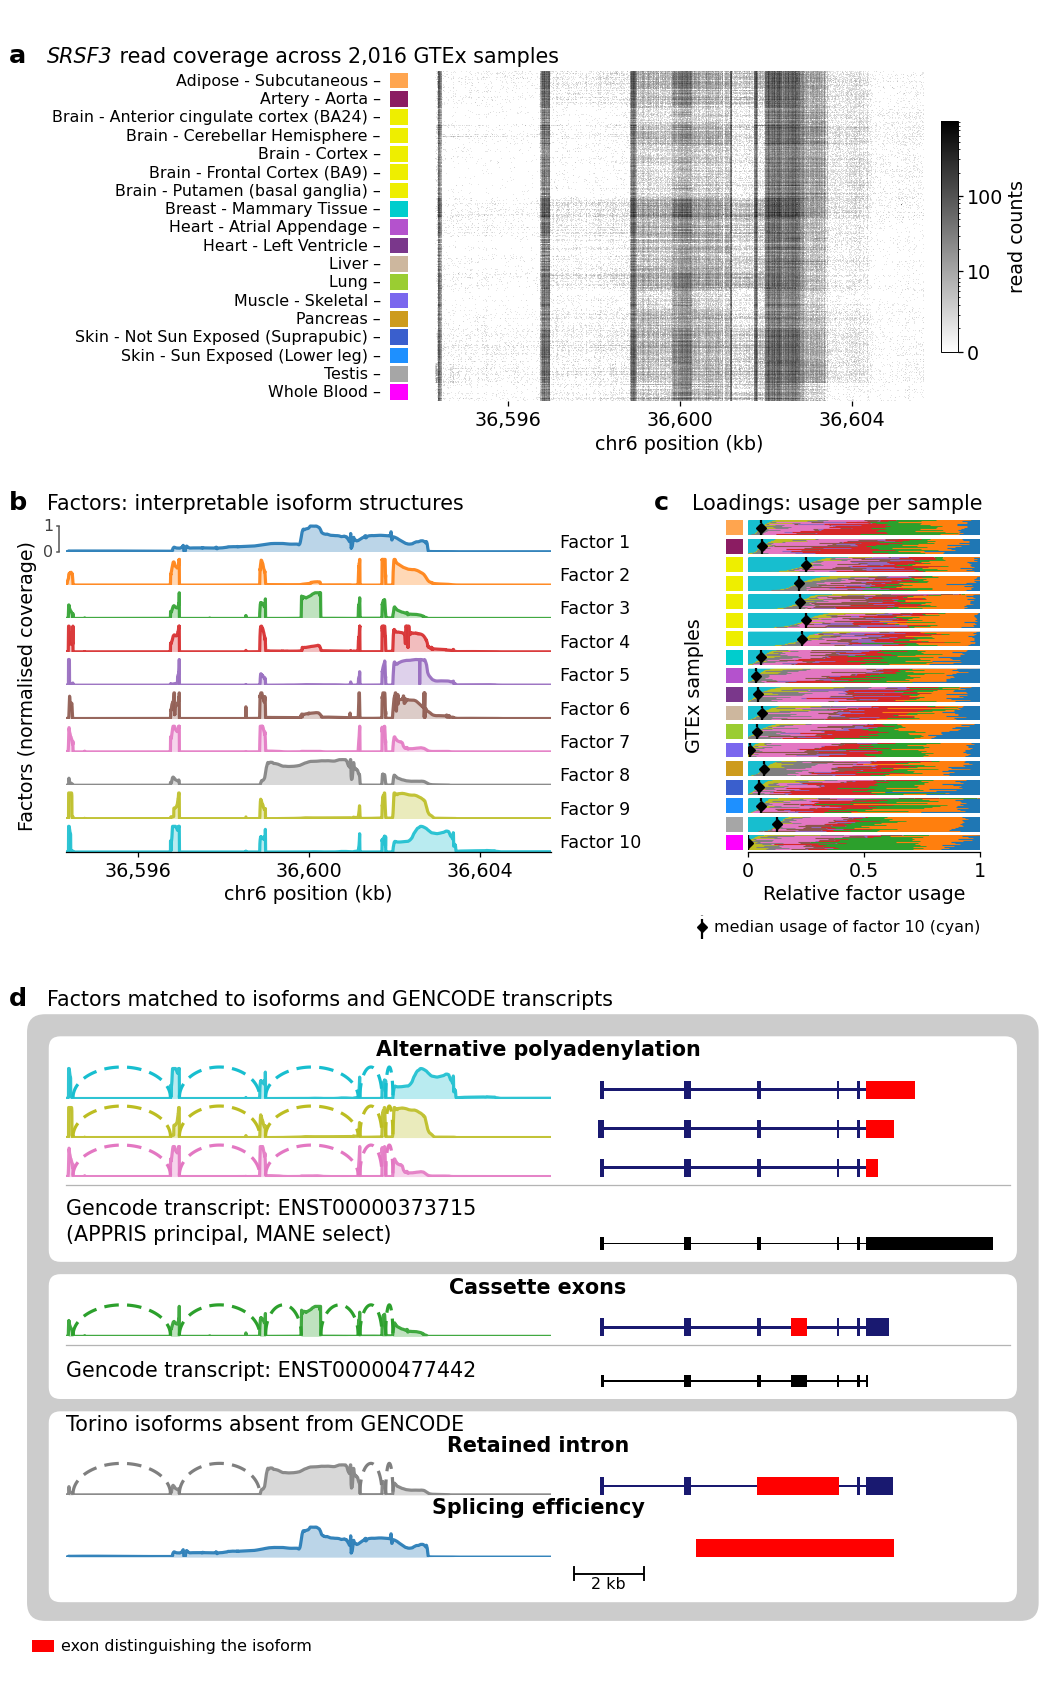

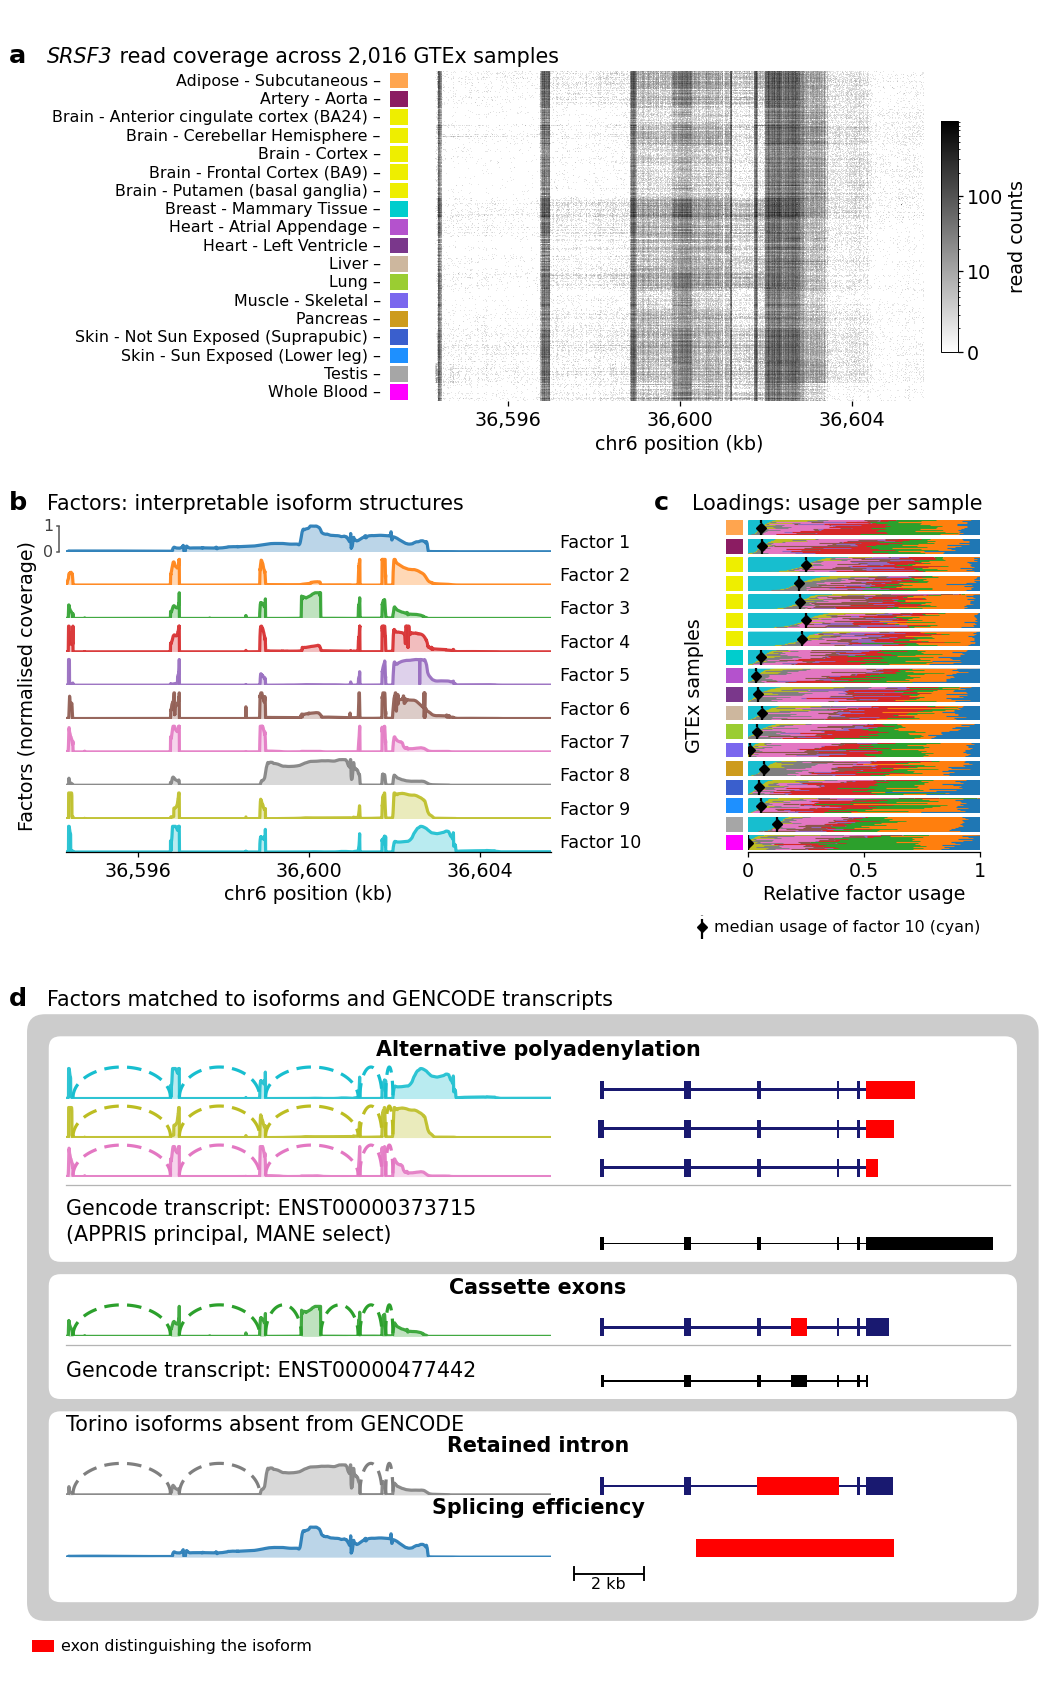

: 

In [ ]:
# -- The page plan, in millimetres, top-left origin ---------------------
# PAGE_W came from panel d's columns; every other panel is fitted to it.
# -- Panel a ------------------------------------------------------------
# The tissue names now sit beside their colour blocks, so panel a's width is
# split between the labels and the heatmap. `_fit_panel_a` picks the label size
# and gives the 4:3 heatmap whatever width is left, shrinking the labels only
# if 18 of them would not fit down the heatmap's height.
A_LABEL_GAP = 1.0
A_STRIP_W = 2.0
A_STRIP_GAP = 3.0
A_CBAR_GAP = 2.0
A_CBAR_W = 1.8
A_CBAR_LABEL_W = 9.0               # ticks + the rotated "read counts" label
A_LABEL_LEADING = 1.15             # line pitch, as a multiple of the font size
A_LABEL_FS_FLOOR = 4.4


def _text_mm(txt, fs_design, style='normal'):
    """Width of `txt` in *design* mm at a design point size.

    Everything in the layout is design mm, so measurement must be too: measuring
    at the on-page (scaled) size would return physical mm and silently shrink
    whatever was fitted against it.
    """
    f = MplFigure(figsize=(1, 1), dpi=100)
    FigureCanvasAgg(f)
    w = f.canvas.get_renderer().get_text_width_height_descent(
        txt, FontProperties(size=fs_design, style=style), False)[0]
    return w / 100 * 25.4


def _max_label_mm(fs):
    """Width of the longest tissue label at `fs` design points, in design mm."""
    f = MplFigure(figsize=(1, 1), dpi=100)
    FigureCanvasAgg(f)
    rend = f.canvas.get_renderer()
    w = max(rend.get_text_width_height_descent(t + ' \u2013', FontProperties(size=fs), False)[0]
            for t in tissues_display)
    return w / 100 * 25.4


# Panel a is compressed vertically only: its width is unchanged, so the heatmap
# is no longer 4:3. A_HEIGHT_SCALE = 1.0 restores the 4:3 shape.
A_HEIGHT_SCALE = 0.90


def _fit_panel_a():
    """(label size, label width, heatmap width, heatmap height).

    Two passes, so that compressing the height does not move anything sideways:

    1. Fit the uncompressed panel -- the label size that lets 18 labels run down
       a 4:3 heatmap, and the width that leaves for the heatmap. These set every
       x position in panel a.
    2. Scale the height by A_HEIGHT_SCALE, holding that width, and shrink the
       label size further if 18 no longer fit the shorter heatmap.

    Letting pass 2 feed back into the width would partly undo the compression:
    smaller labels leave more room, the heatmap widens, and 4:3 makes it taller
    again (a 10% cut came out as 6%).
    """
    avail = PAGE_W - MARGIN_L - MARGIN_R
    fixed = (A_LABEL_GAP + A_STRIP_W + A_STRIP_GAP
             + A_CBAR_GAP + A_CBAR_W + A_CBAR_LABEL_W)
    need = lambda size: len(tissues_display) * size * 0.3528 * A_LABEL_LEADING

    fs = FS_SMALL / PAGE_SCALE          # work in design points
    while True:
        lw = _max_label_mm(fs)
        w = avail - lw - fixed
        if w * 3 / 4 >= need(fs) or fs <= A_LABEL_FS_FLOOR:
            break
        fs -= 0.1

    h = w * 3 / 4 * A_HEIGHT_SCALE
    while fs > A_LABEL_FS_FLOOR and h < need(fs):
        fs -= 0.1
    return fs * PAGE_SCALE, lw, w, h    # font drawn on-page, widths in design mm


A_LABEL_FS, A_LABEL_W, A_HEAT_W, A_HEAT_H = _fit_panel_a()
A_SIDE_W = A_LABEL_W + A_LABEL_GAP + A_STRIP_W

ROW_A_XLABEL = 5.0
ROW_A_H = A_HEAT_H + ROW_A_XLABEL

# Panels b and c share one plotting block, so their top and bottom plot edges
# line up; each panel's axis and label live in the strip below it.
#
# b/c has its own row height: 90% of panel d's. Panels b and d no longer show
# their factor tracks at identical size -- set BC_ROW_SCALE = 1.0 to relock them.
BC_ROW_SCALE = 0.90 * 0.95   # 90%, then a further 95%
BC_ROW_MM = D_ROW_MM * BC_ROW_SCALE
ROW_BC_PLOT_H = K_factors * BC_ROW_MM
ROW_BC_XLABEL = 10.5               # axis + label + panel c's median key
ROW_BC_H = ROW_BC_PLOT_H + ROW_BC_XLABEL
C_KEY_DY = 6.8                     # from the plot block down to the key
C_KEY_H = 3.0

KEY_H = 5.0                        # key strip under panel d

GAP_A_BC, GAP_BC_D = 4.0, 3.5   # halved to tighten the row spacing

C_GAP_FROM_B = 16.0                # separation between panels b and c
C_BAR_W = 34.31 * 0.75             # 3/4 of the previous bar width

D_H = d_vertical_plan()[1] * D_ROW_MM

# Each row is preceded by a band holding its letter and title.
Y_A_BAND = MARGIN_T
Y_A = Y_A_BAND + TITLE_BAND
Y_BC_BAND = Y_A + ROW_A_H + GAP_A_BC
Y_BC = Y_BC_BAND + TITLE_BAND
Y_D_BAND = Y_BC + ROW_BC_H + GAP_BC_D
Y_D = Y_D_BAND + TITLE_BAND

PAGE_H = Y_D + D_H + KEY_H + MARGIN_B


def build_figure():
    assert abs(PAGE_W - DESIGN_W) < 0.05, f'DESIGN_W is stale: {PAGE_W:.2f}'
    fig = plt.figure(figsize=(PAGE_W * MM * PAGE_SCALE,
                              PAGE_H * MM * PAGE_SCALE))

    def rect(x, y, w, h):
        """(x, y) is the top-left corner, in mm from the top-left of the page."""
        return [x / PAGE_W, (PAGE_H - y - h) / PAGE_H, w / PAGE_W, h / PAGE_H]

    def head(x, y_band, letter, title):
        """Panel letter and its title, sharing one baseline.

        `*runs*` are drawn as separate italic Text objects laid end to end, so
        every string stays a plain editable string in the PDF.
        """
        yb = (PAGE_H - y_band - TITLE_BASELINE) / PAGE_H
        fig.text(x / PAGE_W, yb, letter, fontsize=FS_PANEL,
                 fontweight='bold', va='baseline', ha='left')
        cx = x + TITLE_GAP_X
        for i, run in enumerate(title.split('*')):
            if not run:
                continue
            style = 'italic' if i % 2 else 'normal'
            fig.text(cx / PAGE_W, yb, run, fontsize=FS_TITLE, style=style,
                     va='baseline', ha='left')
            cx += _text_mm(run, FS_TITLE / PAGE_SCALE, style)

    def vtext(x, y, text):
        fig.text(x / PAGE_W, (PAGE_H - y) / PAGE_H, text, rotation=90,
                 ha='center', va='center', fontsize=FS_BASE)

    # -- Geometry shared by panels b and d ------------------------------
    trk_x = MARGIN_L + D_CONT_PAD + D_BOX_PAD_L
    mod_x = trk_x + D_TRACK_W + D_COL_GAP

    # -- a: counts, spanning the page width -----------------------------
    side_x = MARGIN_L
    heat_x = side_x + A_SIDE_W + A_STRIP_GAP
    cbar_x = heat_x + A_HEAT_W + A_CBAR_GAP
    ax_a_heat = fig.add_axes(rect(heat_x, Y_A, A_HEAT_W, A_HEAT_H))
    ax_a_side = fig.add_axes(rect(side_x, Y_A, A_SIDE_W, A_HEAT_H))
    cax_a = fig.add_axes(rect(cbar_x, Y_A + A_HEAT_H * 0.15,
                              A_CBAR_W, A_HEAT_H * 0.70))
    panel_a(ax_a_side, ax_a_heat, cax_a, A_LABEL_FS)

    # -- b: factor tracks, directly above panel d's tracks --------------
    axes_b = [fig.add_axes(rect(trk_x, Y_BC + i * BC_ROW_MM, D_TRACK_W, BC_ROW_MM))
              for i in range(K_factors)]
    panel_b(axes_b)
    vtext(trk_x - 4.2, Y_BC + K_factors * BC_ROW_MM / 2,
          'Factors (normalised coverage)')

    # -- c: stacked loadings ---------------------------------------------
    # Left-aligned and 3/4 of its former width, so it stops short of the right
    # margin; its 18 tissue rows fill exactly panel b's vertical extent.
    c_label_x = trk_x + D_TRACK_W + C_GAP_FROM_B
    c_chip_x = c_label_x + 3.5
    c_bar_x = c_chip_x + 2.4
    c_bar_w = C_BAR_W
    tissue_h = ROW_BC_PLOT_H / n_tissues_h
    axes_c_bars, axes_c_blocks = [], []
    for j in range(n_tissues_h):
        y = Y_BC + j * tissue_h
        pad = tissue_h * 0.10
        axes_c_blocks.append(fig.add_axes(rect(c_chip_x, y + pad, 1.8, tissue_h - 2 * pad)))
        axes_c_bars.append(fig.add_axes(rect(c_bar_x, y + pad, c_bar_w, tissue_h - 2 * pad)))
    ax_c_axis = fig.add_axes(rect(c_bar_x, Y_BC + ROW_BC_PLOT_H, c_bar_w, 1e-4))
    panel_c(axes_c_bars, axes_c_blocks, ax_c_axis)
    vtext(c_label_x, Y_BC + ROW_BC_PLOT_H / 2, 'GTEx samples')
    panel_c_key(fig.add_axes(rect(c_label_x, Y_BC + ROW_BC_PLOT_H + C_KEY_DY,
                                  PAGE_W - MARGIN_R - c_label_x, C_KEY_H)))

    # -- d: isoform identification --------------------------------------
    panel_d(fig, rect, MARGIN_L, Y_D)

    # -- Key strip under panel d ------------------------------------------
    ax_key = fig.add_axes(rect(MARGIN_L, Y_D + D_H + 0.8,
                               PAGE_W - MARGIN_L - MARGIN_R, KEY_H - 1.0))
    ax_key.set_xlim(0, PAGE_W - MARGIN_L - MARGIN_R)
    ax_key.set_ylim(0, 1)
    ax_key.axis('off')
    ax_key.add_patch(Rectangle((0.6, 0.34), 2.4, 0.34, facecolor=C_HIGHLIGHT,
                               edgecolor='none'))
    ax_key.text(3.8, 0.5, 'exon distinguishing the isoform', fontsize=FS_TINY,
                va='center', ha='left')

    # -- Panel letters and titles ----------------------------------------
    head(1.0, Y_A_BAND, PANEL_LETTERS[0], PANEL_TITLES[0])
    head(1.0, Y_BC_BAND, PANEL_LETTERS[1], PANEL_TITLES[1])
    head(c_label_x - 4.5, Y_BC_BAND, PANEL_LETTERS[2], PANEL_TITLES[2])
    head(1.0, Y_D_BAND, PANEL_LETTERS[3], PANEL_TITLES[3])
    return fig

fig = build_figure()
fig

## Export

In [ ]:
fig.savefig('Figure1_publication3.pdf')
fig.savefig('Figure1_publication3.svg')
fig.savefig('Figure1_publication3.png', dpi=400)
w_mm, h_mm = (x * 25.4 for x in fig.get_size_inches())
print(f'Saved .pdf / .svg / .png  ({w_mm:.1f} x {h_mm:.1f} mm)')
print(f'  layout {PAGE_W:.2f} x {PAGE_H:.2f} mm scaled by {PAGE_SCALE:.4f}')
print(f'  height is over the 240 mm limit by {h_mm - 240:.1f} mm'
      if h_mm > 240 else f'  {240 - h_mm:.1f} mm inside the 240 mm limit')
print(f'  PDF text: core fonts = {USE_CORE_FONTS} (editable in Inkscape)')


## Notes and deviations

**Reporting added for Nature Genetics**

* *Normalisation is now stated and scaled.* Every factor track (panels b and d)
  is that factor's coverage divided by its own 99th percentile and clipped at
  1. Panel b carries a 0-1 scale on its top track, and the y-label reads
  "Factors (normalised coverage)". One scale serves all twenty tracks because
  they share `TRACK_YMAX`. **1 = the factor's 99th percentile, not a read
  count** -- worth spelling out in the caption.
* *Genomic coordinates.* Panels a and b share one axis, `chr6` position in kb.
  The heatmap's columns are 10 bp bins over the same window as the factor
  tracks (1,134 bins x 10 bp = 11,340 bp vs the tracks' 11,338 bp), so the same
  ticks apply to both; `COORD_TICK_KB` and `CHROM` set them. Panel d's model
  column runs at a different bp-per-mm, so it gets its own 2 kb scale bar
  (`D_SCALEBAR_BP`) rather than a shared axis.
* *The visual codes are now keyed.* Panel c's black diamond and dashed line
  (the median usage of factor 10, the first stacked segment) and the red exons
  in panel d. The bottom box of panel d is titled "Torino isoforms absent from
  GENCODE", which says what it holds without needing a separate gloss.
* *Panel c's x-axis* reads "Relative factor usage" -- the loadings are
  proportions summing to 1, which "weights" did not convey.

**Still open (not applied):** five brain regions share one GTEx yellow, so
their labelled blocks in panel a are indistinguishable; and `tab10` puts the
green cassette factor next to the red highlight in panel d, the worst pairing
for deuteranopia.


**Consequences of the narrow page, worth knowing:**

* The track column and the model column no longer share one bp-per-mm scale.
  Holding both `D_TRACK_W` (panel b's width) and `D_MODEL_W` fixed while the
  model axis covers the Gencode range forces them apart. Widening `D_MODEL_W`
  to ~62 mm would re-align them, at the cost of the reference width.
* Panel a's heatmap is small (~54 x 41 mm) because the tissue names claim
  ~39 mm of the page width. Moving the colour bar under the heatmap, or
  abbreviating the tissue names, would buy the heatmap most of that back.

**Faithful to `Fig1_alt.png`:** factor tracks are `tab10[factor - 1]` at
`alpha=0.9` (fill `alpha=0.3`); Torino exons `midnightblue` with the
distinguishing exon in `red`; Gencode models `black`; container `#cccccc` on
white boxes; models bottom-aligned in their row, level with the track baseline.

**Export note.** Save with the default (`standard`) bbox, never
`bbox_inches='tight'`: panel d's container, white boxes and divider rules are
figure-level artists, invisible to the tight-bbox pass, so a tight save crops
them away.

**Performance note.** All ~2,000 x 10 loading segments of a tissue go into a
single rasterised `LineCollection`; splitting them per factor produces ~180
rasterised groups and kills the kernel on PDF export.

**Main tuning knobs**

* Reference widths: `D_TRACK_W`, `D_MODEL_W`, `D_COL_GAP` -- these set `PAGE_W`.
* Heights: `D_ROW_MM` scales panels b, c and d together; `GAP_A_BC`,
  `GAP_BC_D`, `ROW_A_TITLE`, `ROW_BC_XLABEL` set the rhythm. `PAGE_H` follows.
* Panel a: `A_CBAR_LABEL_W`, `A_LABEL_GAP`, `A_LABEL_FS_FLOOR`; the heatmap
  size is derived by `_fit_panel_a`.
* Panel c: `C_BAR_W` and `C_GAP_FROM_B`.
* Panel d spacing: `D_GEN_SEP`, `D_DIVIDER_COLOR`, `D_DIVIDER_LW`.
